# Phase 2: Liver segmentation (charvi, patient 1)

| | This member's algorithms |
|---|---|
| Morphology | custom **cross** and hand-made **octagon** structuring elements |
| Method A | **adaptive local thresholding** (`threshold_local`) + morphology |
| Method B | **seeded region growing** from the **spatial centroid** of the liver core, then dark tumour regions inside the liver outline are added (the ground-truth liver includes the tumour) |
| Validation | Dice + IoU against the ground-truth liver |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

from scipy import ndimage as ndi
from skimage.filters import threshold_local

NAME = "charvi"
ENH = "../phase1/outputs_charvi/enhanced"
GT = f"../data/slices/{NAME}"
OUT = "outputs_charvi"
FIGS = "../report/figures/charvi"
FAILED = "../report/failed_cases/charvi"
for d in [f"{OUT}/adaptive", f"{OUT}/regiongrow", FIGS, FAILED]:
    os.makedirs(d, exist_ok=True)

files = sorted(glob.glob(f"{ENH}/*_enh.png"))
print(len(files), "enhanced slices found")

def load(p):
    sid = os.path.basename(p).replace("_enh.png", "")
    return sid, cv2.imread(p, 0), cv2.imread(f"{GT}/{sid}_liver.png", 0) > 0

def dice(pred, gt):
    """Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none."""
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-9)

def iou(pred, gt):
    """Jaccard / IoU = |A n B| / |A u B|."""
    return (pred & gt).sum() / ((pred | gt).sum() + 1e-9)

def overlay(img, pred, gt):
    """RED = predicted outline, GREEN = ground-truth outline."""
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for mask, colour in [(gt, (0, 255, 0)), (pred, (255, 0, 0))]:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, colour, 2)
    return rgb

def keep_liver(mask):
    """Biggest blob on the image's left side (the liver is on the patient's right)."""
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    best, best_area = 0, 0
    for i in range(1, n):
        if centroids[i][0] < 0.6 * mask.shape[1] and stats[i, cv2.CC_STAT_AREA] > best_area:
            best, best_area = i, stats[i, cv2.CC_STAT_AREA]
    return labels == best if best else np.zeros(mask.shape, bool)

example = max(files, key=lambda f: load(f)[2].sum())
sid, img, gt = load(example)
print("example slice:", sid)

18 enhanced slices found
example slice: p1_s65


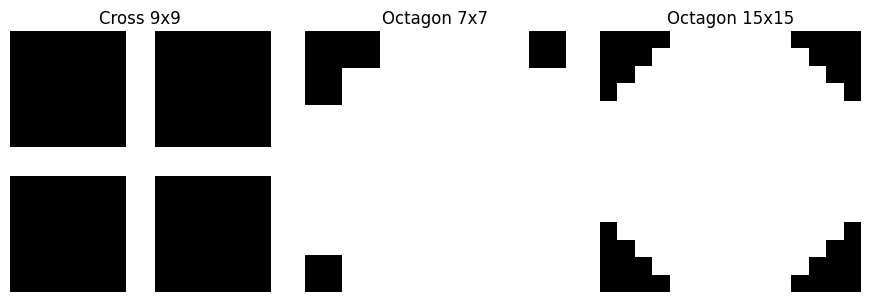

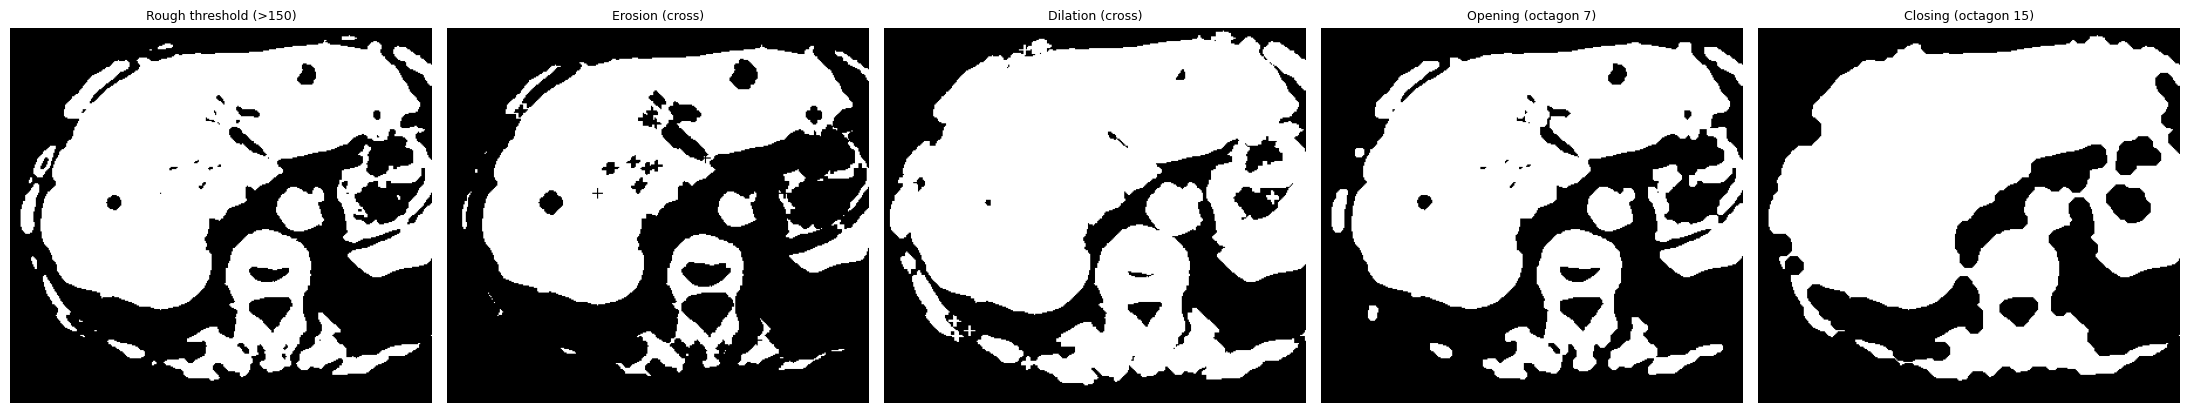

In [2]:
SE_CROSS_9 = cv2.getStructuringElement(cv2.MORPH_CROSS, (9, 9))
SE_OCTAGON_15 = np.ones((15, 15), np.uint8)                       # hand-made octagon: square with cut corners
for r in range(15):
    for c in range(15):
        if min(r, 14 - r) + min(c, 14 - c) < 4:
            SE_OCTAGON_15[r, c] = 0
SE_OCTAGON_7 = cv2.resize(SE_OCTAGON_15, (7, 7), interpolation=cv2.INTER_NEAREST)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, se, t in zip(ax, [SE_CROSS_9, SE_OCTAGON_7, SE_OCTAGON_15], ["Cross 9x9", "Octagon 7x7", "Octagon 15x15"]):
    a.imshow(se, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

rough = (img > 150).astype(np.uint8)
ops = {"Rough threshold (>150)": rough,
       "Erosion (cross)": cv2.erode(rough, SE_CROSS_9),
       "Dilation (cross)": cv2.dilate(rough, SE_CROSS_9),
       "Opening (octagon 7)": cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_OCTAGON_7),
       "Closing (octagon 15)": cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_OCTAGON_15)}
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, (t, m) in zip(ax, ops.items()):
    a.imshow(m[100:420, 40:400], cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_morphology.png", dpi=120); plt.show()

**Method A: adaptive local thresholding.** Instead of one threshold for the whole image, every pixel gets its own threshold = the mean brightness of the 251x251 window around it. A pixel counts as "liver-like" if it is brighter than its local mean and brighter than 120 (to ignore fat and muscle). Morphology then cuts thin links, `keep_liver` keeps the liver blob, and closing + hole filling tidy it.

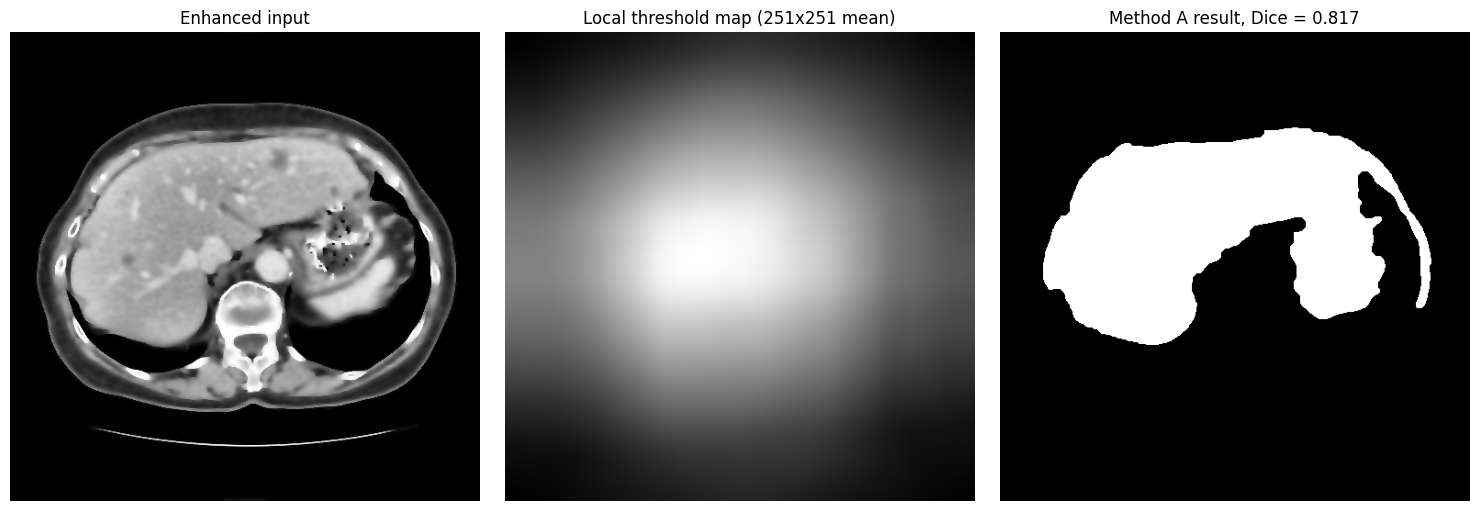

In [3]:
def segment_adaptive(img, block=251, floor=120):
    t = threshold_local(img, block_size=block, method="mean", offset=0)     # one threshold per pixel
    mask = ((img > t) & (img > floor)).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, SE_OCTAGON_7)
    mask = keep_liver(mask > 0)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_15)
    return ndi.binary_fill_holes(mask > 0)

local_t = threshold_local(img, block_size=251, method="mean")
pred_a = segment_adaptive(img)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Enhanced input")
ax[1].imshow(local_t, cmap="gray"); ax[1].set_title("Local threshold map (251x251 mean)")
ax[2].imshow(pred_a, cmap="gray"); ax[2].set_title(f"Method A result, Dice = {dice(pred_a, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_a_adaptive.png", dpi=120); plt.show()

**Method B: seeded region growing.** 1) Seed: the **spatial centroid** of the solid liver-coloured core (if the centroid falls outside a curved core, the core pixel nearest to it). 2) Grow outwards, adding neighbours whose brightness is within 30 of the region's average. 3) Clean up with opening, `keep_liver`, closing and hole filling. 4) **Add the tumour:** region growing only takes normal (bright) liver, but the LiTS liver label includes the tumour. A big closing (61 x 61 octagon) draws the liver outline across the "bites" a dark tumour makes at the edge; tumour-grey pixels inside that outline (darker than liver, brighter than fat) are added to the liver.

In [4]:
def region_grow(img, seed, tolerance, allowed=None):
    """Seeded region growing: start at the seed pixel and keep adding 4-neighbours whose
    brightness is within `tolerance` of the region's running average."""
    h, w = img.shape
    region = np.zeros((h, w), bool)
    region[seed] = True
    stack, total, count = [seed], float(img[seed]), 1
    while stack:
        y, x = stack.pop()
        for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            yy, xx = y + dy, x + dx
            if 0 <= yy < h and 0 <= xx < w and not region[yy, xx] and (allowed is None or allowed[yy, xx]):
                if abs(float(img[yy, xx]) - total / count) <= tolerance:
                    region[yy, xx] = True
                    stack.append((yy, xx))
                    total += float(img[yy, xx]); count += 1
    return region

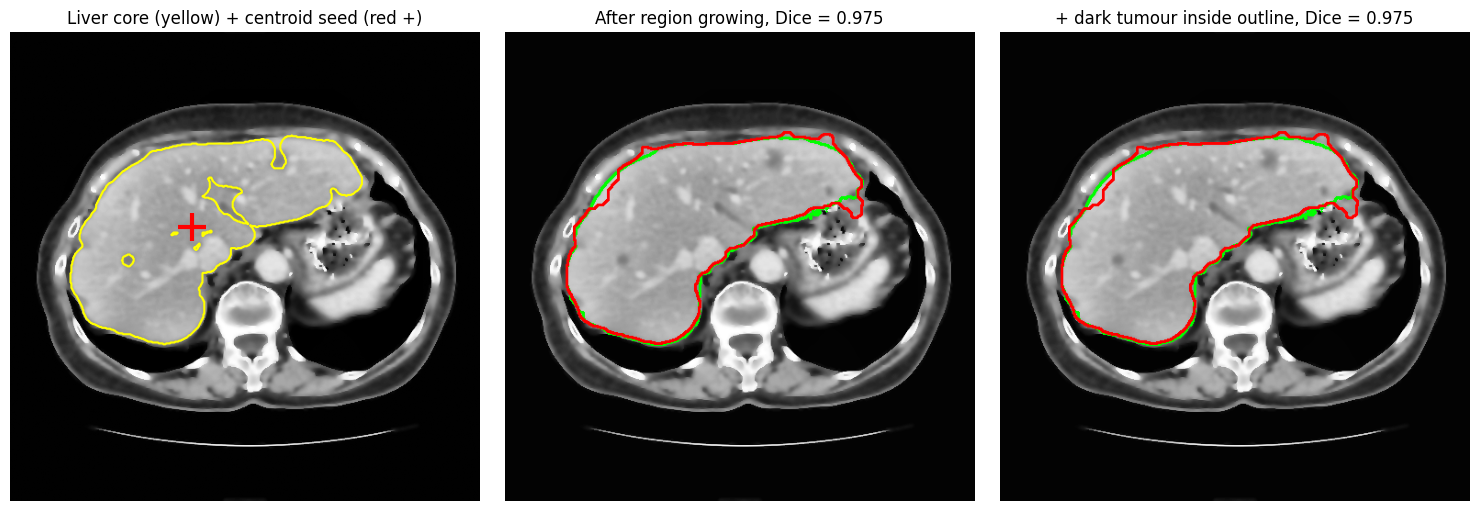

In [5]:
LIVER_LOW, LIVER_HIGH, TOLERANCE = 150, 225, 30
FAT_LEVEL = 60                                                    # darker than this = fat / air, never liver or tumour
SE_OCTAGON_61 = cv2.resize(SE_OCTAGON_15, (61, 61), interpolation=cv2.INTER_NEAREST)   # big octagon for the outline

def liver_core(img):
    band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)
    return keep_liver(cv2.morphologyEx(band, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))))

def find_seed(img):
    """Seed = spatial centroid of the liver core (nearest core pixel if the centroid itself is outside the core)."""
    core = liver_core(img)
    if not core.any():
        return None
    ys, xs = np.nonzero(core)
    cy, cx = ys.mean(), xs.mean()                                  # centroid of the core
    i = np.argmin((ys - cy) ** 2 + (xs - cx) ** 2)
    return ys[i], xs[i]

def add_tumour(img, liver):
    """Take in the dark tumour that region growing leaves out: tumour-grey pixels inside the closed liver outline."""
    outline = ndi.binary_fill_holes(cv2.morphologyEx(liver.astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_61) > 0)
    dark = outline & ~liver & (img >= FAT_LEVEL) & (img < LIVER_LOW)
    dark = cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, SE_OCTAGON_7) > 0              # drop thin slivers
    joined = cv2.morphologyEx((liver | dark).astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_15) > 0
    return keep_liver(ndi.binary_fill_holes(joined))

def segment_region_growing(img, return_steps=False):
    seed = find_seed(img)
    if seed is None:
        return np.zeros(img.shape, bool)
    grown = region_grow(cv2.GaussianBlur(img, (5, 5), 0), seed, TOLERANCE)
    mask = cv2.morphologyEx(grown.astype(np.uint8), cv2.MORPH_OPEN, SE_OCTAGON_7) > 0
    mask = cv2.morphologyEx(keep_liver(mask).astype(np.uint8), cv2.MORPH_CLOSE, SE_OCTAGON_15)
    grown_liver = ndi.binary_fill_holes(mask > 0)
    final = add_tumour(img, grown_liver)
    return (final, seed, grown_liver) if return_steps else final

pred_b, seed, grown_liver = segment_region_growing(img, return_steps=True)
core = liver_core(img)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray"); ax[0].contour(core, [0.5], colors="yellow")
ax[0].plot(seed[1], seed[0], "r+", markersize=20, mew=3); ax[0].set_title("Liver core (yellow) + centroid seed (red +)")
ax[1].imshow(overlay(img, grown_liver, gt)); ax[1].set_title(f"After region growing, Dice = {dice(grown_liver, gt):.3f}")
ax[2].imshow(overlay(img, pred_b, gt)); ax[2].set_title(f"+ dark tumour inside outline, Dice = {dice(pred_b, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_b_regiongrow.png", dpi=120); plt.show()

In [6]:
rows = []
for f in files:
    sid, img, gt = load(f)
    for method, fn in [("adaptive", segment_adaptive), ("regiongrow", segment_region_growing)]:
        pred = fn(img)
        cv2.imwrite(f"{OUT}/{method}/{sid}_liver_pred.png", pred.astype(np.uint8) * 255)
        rows.append({"slice": sid, "method": method, "Dice": dice(pred, gt), "IoU": iou(pred, gt), "GT liver pixels": int(gt.sum())})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase2_metrics.csv", index=False)
print(results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"]).round(3))
print("\nPer slice Dice:")
print(results.pivot(index="slice", columns="method", values="Dice").round(3))

             Dice                 IoU             
             mean    std   min   mean    std   min
method                                            
adaptive    0.756  0.204  0.02  0.637  0.191  0.01
regiongrow  0.886  0.224  0.00  0.836  0.219  0.00

Per slice Dice:
method  adaptive  regiongrow
slice                       
p1_s56     0.834       0.840
p1_s57     0.503       0.915
p1_s58     0.851       0.957
p1_s59     0.811       0.959
p1_s60     0.808       0.963
p1_s61     0.724       0.958
p1_s62     0.759       0.955
p1_s63     0.769       0.955
p1_s64     0.812       0.971
p1_s65     0.817       0.975
p1_s66     0.829       0.950
p1_s67     0.874       0.972
p1_s68     0.877       0.949
p1_s69     0.913       0.962
p1_s70     0.844       0.883
p1_s71     0.832       0.912
p1_s72     0.725       0.870
p1_s73     0.020       0.000


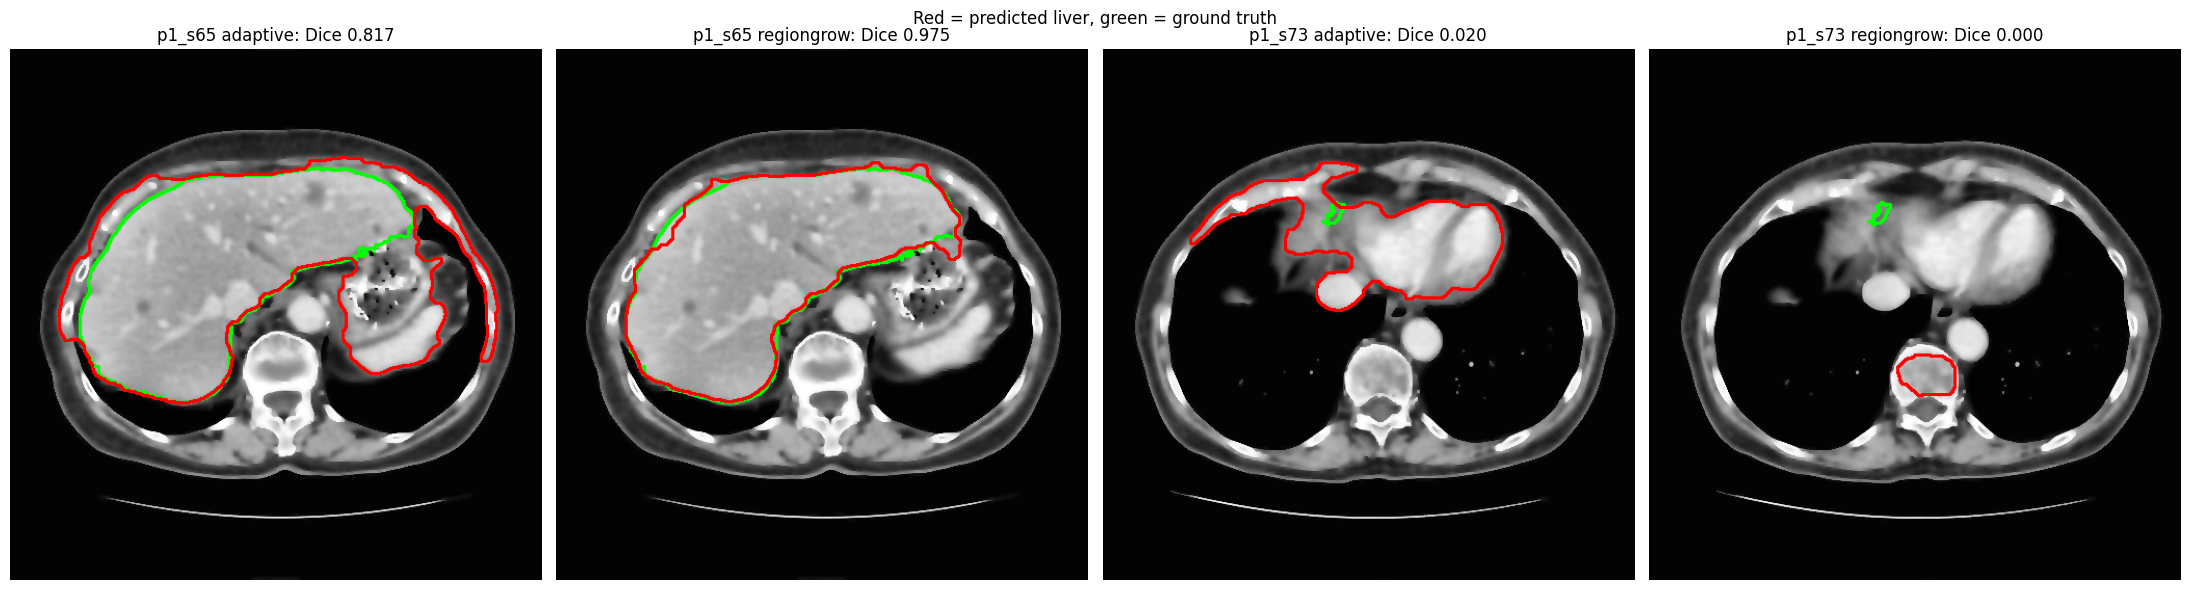

In [7]:
rg = results[results.method == "regiongrow"].set_index("slice")["Dice"]
best_sid, worst_sid = rg.idxmax(), rg.idxmin()
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (s, method) in zip(ax, [(best_sid, "adaptive"), (best_sid, "regiongrow"), (worst_sid, "adaptive"), (worst_sid, "regiongrow")]):
    _, img, gt = load(f"{ENH}/{s}_enh.png")
    pred = cv2.imread(f"{OUT}/{method}/{s}_liver_pred.png", 0) > 0
    a.imshow(overlay(img, pred, gt)); a.axis("off"); a.set_title(f"{s} {method}: Dice {dice(pred, gt):.3f}")
plt.suptitle("Red = predicted liver, green = ground truth")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_overlays.png", dpi=120); plt.show()

In [8]:
# ---- failed cases: every slice where the final method scored Dice < 0.7, with MEASURED reasons ----
best_method = results.groupby("method")["Dice"].mean().idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]

def first_step(img, liver):
    """The liver core the centroid seed is taken from."""
    return liver_core(img)

def hu(ct, mask):
    return float(np.median(ct[mask])) if mask.any() else float("nan")

def diagnose(sid, img, liver, pred, gt):
    """Measure why the slice failed: size, contrast in HU, position, and which pipeline step went wrong."""
    ct = np.load(f"{GT}/{sid}_ct.npy")
    missed, leaked = gt & ~pred, pred & ~gt
    reasons = []
    if "liver" == "tumour":
        ref = liver & ~gt                                                     # normal liver around the tumour
        contrast, noise = hu(ct, ref) - hu(ct, gt), ct[ref].std()
        if gt.sum() < 300:
            reasons.append(f"small tumour ({int(gt.sum())} px): partial-volume effect, its edge HU blends into the liver")
        reasons.append(f"tumour {contrast:.0f} HU darker than liver, liver noise {noise:.0f} HU (contrast/noise {contrast / noise:.2f}"
                       + (", LOW)" if contrast / noise < 1 else ")"))
        in_roi = (gt & liver_roi(liver)).sum() / max(gt.sum(), 1)
        if in_roi < 0.8:
            reasons.append(f"{1 - in_roi:.0%} of the tumour lies in the liver rim that is left out of the search area")
    else:
        ref = cv2.dilate(gt.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool) & ~gt   # tissue just outside the liver
        if gt.sum() < 5000:
            reasons.append(f"small liver cross-section ({int(gt.sum())} px): near the dome or tip, partial volume with neighbours")
    start = first_step(img, liver)
    if not (start & gt).any():
        reasons.append("step that failed: liver core / centroid seed (nothing started on the liver)")
    elif not (pred & gt).any():
        reasons.append("step that failed: clean-up after liver core / centroid seed removed everything it found on the liver")
    elif leaked.sum() >= missed.sum():
        reasons.append(f"step that failed: region growing leaked {int(leaked.sum())} px into tissue of {hu(ct, leaked):.0f} HU "
                       f"(liver {hu(ct, gt):.0f} HU, neighbours {hu(ct, ref):.0f} HU): similar HU, no edge to stop at")
    else:
        reasons.append(f"step that failed: region growing stopped early, missed {int(missed.sum())} px of {hu(ct, missed):.0f} HU "
                       f"(found part {hu(ct, pred & gt):.0f} HU)")
    return "; ".join(reasons), ct, missed, leaked, ref

lines = [f"# Phase 2 failed cases: {NAME} (liver segmentation)", "",
         f"Final method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.", "",
         "| Slice | Dice ({}) | Ground-truth pixels | Predicted pixels | Measured reasons |".format(best_method),
         "|---|---|---|---|---|"]
for k, (_, row) in enumerate(failed.iterrows()):
    _, img, gt = load(f"{ENH}/{row.slice}_enh.png"); liver = None
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_liver_pred.png", 0) > 0
    why, ct, missed, leaked, ref = diagnose(row.slice, img, liver, pred, gt)
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt.sum())} | {int(pred.sum())} | {why} |")
    if k < 3:                                                   # diagnosis figure for the 3 worst slices
        ys, xs = np.where(gt | pred | (liver if liver is not None else gt))
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        ax[0].imshow(overlay(img, pred, gt)[y0:y1, x0:x1]); ax[0].axis("off")
        ax[0].set_title(f"{row.slice}: red = predicted, green = truth (Dice {row.Dice:.3f})")
        for mask, name, colour in [(gt, "liver (truth)", "green"), (ref, "surrounding tissue", "grey"),
                                   (missed, "missed", "orange"), (leaked, "leaked", "red")]:
            if mask.any():
                ax[1].hist(ct[mask], bins=60, range=(-100, 250), alpha=0.5, density=True, label=f"{name} ({int(mask.sum())} px)", color=colour)
        ax[1].set_xlabel("HU"); ax[1].set_ylabel("density"); ax[1].legend(fontsize=8); ax[1].set_title("HU histograms")
        plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_{row.slice}_{best_method}_diagnosis.png", dpi=110); plt.close()
if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines += ["", "Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file."]
open(f"{FAILED}/{NAME}_phase2_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Phase 2 failed cases: charvi (liver segmentation)

Final method: **regiongrow** (mean Dice 0.886). Slices with Dice < 0.7: 1 of 18.

| Slice | Dice (regiongrow) | Ground-truth pixels | Predicted pixels | Measured reasons |
|---|---|---|---|---|
| p1_s73 | 0.000 | 211 | 1831 | small liver cross-section (211 px): near the dome or tip, partial volume with neighbours; step that failed: liver core / centroid seed (nothing started on the liver) |

Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file.


**Parameter sensitivity.** The key parameter of the final method, **TOLERANCE** (how far a pixel may be from the region's running average and still join the liver), is varied while everything else stays fixed; the mean Dice over all test slices shows how sensitive the result is and whether the chosen value sits on a plateau or a sharp peak.

 TOLERANCE  mean Dice  std Dice
        10      0.336     0.222
        15      0.669     0.212
        20      0.819     0.206
        25      0.871     0.216
        30      0.886     0.218
        35      0.879     0.219
        40      0.869     0.216
        50      0.828     0.209


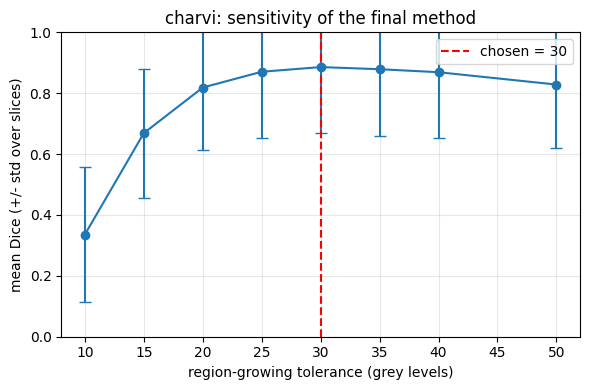

In [9]:
# ---- parameter sensitivity: mean Dice of the final method while TOLERANCE changes ----
chosen = TOLERANCE
sweep = []
for value in [10, 15, 20, 25, 30, 35, 40, 50]:
    TOLERANCE = value                                         # the segmentation function reads this setting
    scores = []
    for f in files:
        sid, img, gt = load(f)
        scores.append(dice(segment_region_growing(img), gt))
    sweep.append({"TOLERANCE": value, "mean Dice": np.mean(scores), "std Dice": np.std(scores)})
TOLERANCE = chosen                                            # put the chosen value back
sweep = pd.DataFrame(sweep)
sweep.to_csv(f"{OUT}/phase2_sensitivity.csv", index=False)
print(sweep.round(3).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.errorbar(sweep["TOLERANCE"], sweep["mean Dice"], yerr=sweep["std Dice"], marker="o", capsize=4)
plt.axvline(chosen, color="red", linestyle="--", label=f"chosen = {chosen}")
plt.xlabel("region-growing tolerance (grey levels)"); plt.ylabel("mean Dice (+/- std over slices)"); plt.ylim(0, 1)
plt.title(f"{NAME}: sensitivity of the final method"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_sensitivity.png", dpi=120); plt.show()